## Step 1: Environment Setup and Library Imports

In this step, we import the core scientific, visualization, and deep learning libraries:
- **TensorFlow & Keras**: Deep learning framework for CNN modeling, image preprocessing, and training.
- **NumPy & Pandas**: Array operations, matrix computations, and data summaries.
- **Matplotlib & Seaborn**: High-quality visual plots for data distributions, sample images, training curves, and confusion matrix.
- **Scikit-Learn**: Comprehensive classification evaluation metrics.
- **PIL & Shutil / OS**: File system operations and image processing.


In [1]:
import os
import sys
import shutil
import zipfile
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from sklearn.metrics import classification_report, confusion_matrix

# Reproducibility seed
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11

print(f"TensorFlow Version: {tf.__version__}")
print(f"NumPy Version:      {np.__version__}")
print(f"GPU Available:      {len(tf.config.list_physical_devices('GPU')) > 0}")


c:\Users\souri krishna\AppData\Local\Programs\Python\Python313\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (7.2.0)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


TensorFlow Version: 2.20.0
NumPy Version:      2.2.6
GPU Available:      False


## Step 2: Data Preparation & Structured Directory Organization

To utilize TensorFlow's `ImageDataGenerator.flow_from_directory()`, we structure the dataset into subdirectories where subfolder names correspond to target class labels:
```
dataset/
├── train/
│   ├── cats/  (1,000 images)
│   └── dogs/  (1,000 images)
├── validation/
│   ├── cats/  (250 images)
│   └── dogs/  (250 images)
└── test/
    ├── cats/  (250 images)
    └── dogs/  (250 images)
```
- **Train Set**: 2,000 images for model weight training.
- **Validation Set**: 500 images for hyperparameter tuning & overfitting monitoring during training.
- **Test Set**: 500 completely unseen images for final evaluation.


In [2]:
BASE_DIR = os.getcwd()
DATASET_DIR = os.path.join(BASE_DIR, 'dataset')
ZIP_URL = 'https://cdn.freecodecamp.org/project-data/cats-and-dogs/cats_and_dogs.zip'
ZIP_PATH = os.path.join(BASE_DIR, 'cats_and_dogs.zip')

def prepare_dataset():
    # 1. Download zip archive if needed
    if not os.path.exists(ZIP_PATH):
        print("Downloading Cats vs Dogs dataset...")
        req = urllib.request.Request(ZIP_URL, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(req) as resp, open(ZIP_PATH, 'wb') as out_file:
            shutil.copyfileobj(resp, out_file)
        print("Download complete.")
    else:
        print("Dataset archive already present.")

    # 2. Extract and organize
    if not os.path.exists(DATASET_DIR):
        print("Extracting and organizing dataset structure...")
        temp_extract = os.path.join(BASE_DIR, 'temp_raw_data')
        with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
            zip_ref.extractall(temp_extract)
        
        raw_root = os.path.join(temp_extract, 'cats_and_dogs')
        
        train_cats_dir = os.path.join(DATASET_DIR, 'train', 'cats')
        train_dogs_dir = os.path.join(DATASET_DIR, 'train', 'dogs')
        val_cats_dir = os.path.join(DATASET_DIR, 'validation', 'cats')
        val_dogs_dir = os.path.join(DATASET_DIR, 'validation', 'dogs')
        test_cats_dir = os.path.join(DATASET_DIR, 'test', 'cats')
        test_dogs_dir = os.path.join(DATASET_DIR, 'test', 'dogs')

        for d in [train_cats_dir, train_dogs_dir, val_cats_dir, val_dogs_dir, test_cats_dir, test_dogs_dir]:
            os.makedirs(d, exist_ok=True)
            
        for f in os.listdir(os.path.join(raw_root, 'train', 'cats')):
            if f.lower().endswith(('.jpg', '.jpeg', '.png')):
                shutil.copy(os.path.join(raw_root, 'train', 'cats', f), train_cats_dir)
                
        for f in os.listdir(os.path.join(raw_root, 'train', 'dogs')):
            if f.lower().endswith(('.jpg', '.jpeg', '.png')):
                shutil.copy(os.path.join(raw_root, 'train', 'dogs', f), train_dogs_dir)

        raw_val_cats = sorted([f for f in os.listdir(os.path.join(raw_root, 'validation', 'cats')) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
        for f in raw_val_cats[:250]:
            shutil.copy(os.path.join(raw_root, 'validation', 'cats', f), val_cats_dir)
        for f in raw_val_cats[250:500]:
            shutil.copy(os.path.join(raw_root, 'validation', 'cats', f), test_cats_dir)

        raw_val_dogs = sorted([f for f in os.listdir(os.path.join(raw_root, 'validation', 'dogs')) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
        for f in raw_val_dogs[:250]:
            shutil.copy(os.path.join(raw_root, 'validation', 'dogs', f), val_dogs_dir)
        for f in raw_val_dogs[250:500]:
            shutil.copy(os.path.join(raw_root, 'validation', 'dogs', f), test_dogs_dir)

        shutil.rmtree(temp_extract)
        print("Dataset extracted and organized successfully!")
    else:
        print("Structured dataset directory already exists.")

prepare_dataset()


Dataset archive already present.
Structured dataset directory already exists.


### Dataset Distribution and Summary Statistics
Let's verify the sample counts across each dataset partition.


Dataset Split     Cats        Dogs        Total Images
Train             1000        1000        2000        
Validation        250         250         500         
Test              250         250         500         


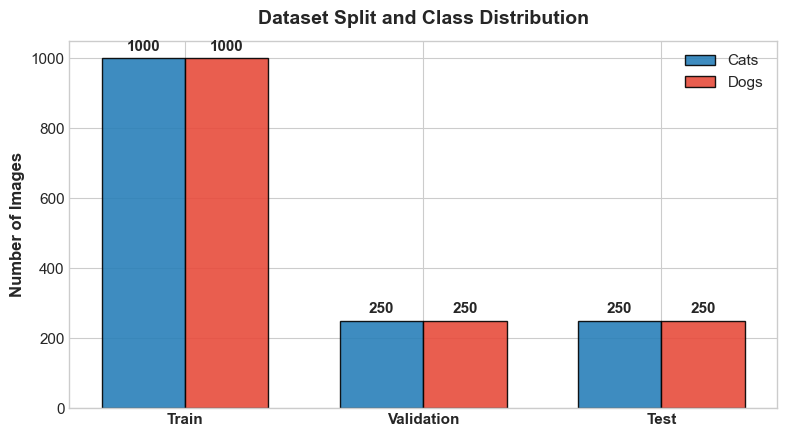

In [3]:
splits = ['train', 'validation', 'test']
classes = ['cats', 'dogs']
counts = {}

for split in splits:
    counts[split] = {}
    for cls in classes:
        folder = os.path.join(DATASET_DIR, split, cls)
        counts[split][cls] = len(os.listdir(folder))

print("=" * 55)
print(f"{'Dataset Split':<18}{'Cats':<12}{'Dogs':<12}{'Total Images':<12}")
print("=" * 55)
for split in splits:
    cat_cnt = counts[split]['cats']
    dog_cnt = counts[split]['dogs']
    tot = cat_cnt + dog_cnt
    print(f"{split.capitalize():<18}{cat_cnt:<12}{dog_cnt:<12}{tot:<12}")
print("=" * 55)

# Visualizing Class Balance
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(splits))
width = 0.35

rects1 = ax.bar(x - width/2, [counts[s]['cats'] for s in splits], width, label='Cats', color='#2980b9', alpha=0.9, edgecolor='black')
rects2 = ax.bar(x + width/2, [counts[s]['dogs'] for s in splits], width, label='Dogs', color='#e74c3c', alpha=0.9, edgecolor='black')

ax.set_ylabel('Number of Images', fontsize=12, fontweight='bold')
ax.set_title('Dataset Split and Class Distribution', fontsize=14, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels([s.capitalize() for s in splits], fontsize=11, fontweight='bold')
ax.legend(fontsize=11)
ax.bar_label(rects1, padding=3, fontweight='bold')
ax.bar_label(rects2, padding=3, fontweight='bold')
plt.tight_layout()
plt.show()


### Visualizing Raw Image Samples
Let's inspect several sample images from both classes in the training set.


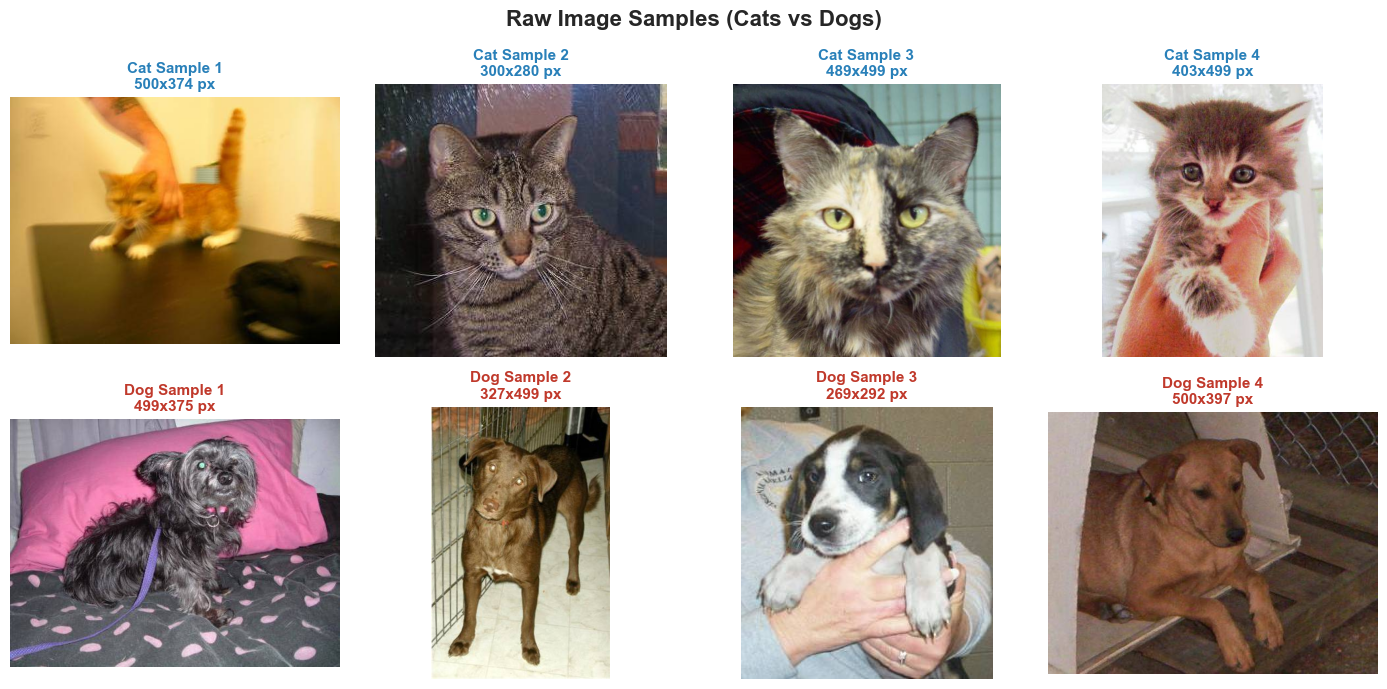

In [4]:
sample_cats = sorted(os.listdir(os.path.join(DATASET_DIR, 'train', 'cats')))[:4]
sample_dogs = sorted(os.listdir(os.path.join(DATASET_DIR, 'train', 'dogs')))[:4]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
fig.suptitle("Raw Image Samples (Cats vs Dogs)", fontsize=16, fontweight='bold', y=0.98)

for i, img_name in enumerate(sample_cats):
    img_path = os.path.join(DATASET_DIR, 'train', 'cats', img_name)
    img = Image.open(img_path)
    axes[0, i].imshow(img)
    axes[0, i].set_title(f"Cat Sample {i+1}\n{img.size[0]}x{img.size[1]} px", fontsize=11, fontweight='bold', color='#2980b9')
    axes[0, i].axis('off')

for i, img_name in enumerate(sample_dogs):
    img_path = os.path.join(DATASET_DIR, 'train', 'dogs', img_name)
    img = Image.open(img_path)
    axes[1, i].imshow(img)
    axes[1, i].set_title(f"Dog Sample {i+1}\n{img.size[0]}x{img.size[1]} px", fontsize=11, fontweight='bold', color='#c0392b')
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()


## Step 3: Data Augmentation and Preprocessing

### 1. Data Augmentation
To prevent overfitting on the 2,000 training images, we configure dynamic on-the-fly transformations using `ImageDataGenerator`:
- **Rotation (`rotation_range=25`)**: Randomly rotates images up to 25 degrees.
- **Width / Height Shifts (`0.2`)**: Randomly shifts images horizontally and vertically by 20%.
- **Shear Range (`0.2`)**: Distorts image perspective along axes.
- **Zoom Range (`0.2`)**: Randomly zooms into images by 20%.
- **Horizontal Flip (`horizontal_flip=True`)**: Flips images horizontally.
- **Fill Mode (`fill_mode='nearest'`)**: Fills empty boundary pixels with nearest pixel values.

### 2. Normalization / Pixel Rescaling
Images are stored as 8-bit unsigned integers $[0, 255]$. We apply `rescale=1./255` to normalize pixel values into the continuous interval $[0.0, 1.0]$. This stabilizes learning rates and gradient steps in Stochastic Gradient Descent (SGD).

> **Important**: Validation and Test datasets are **never augmented**, only normalized (`rescale=1./255`), ensuring evaluation reflects true real-world images.


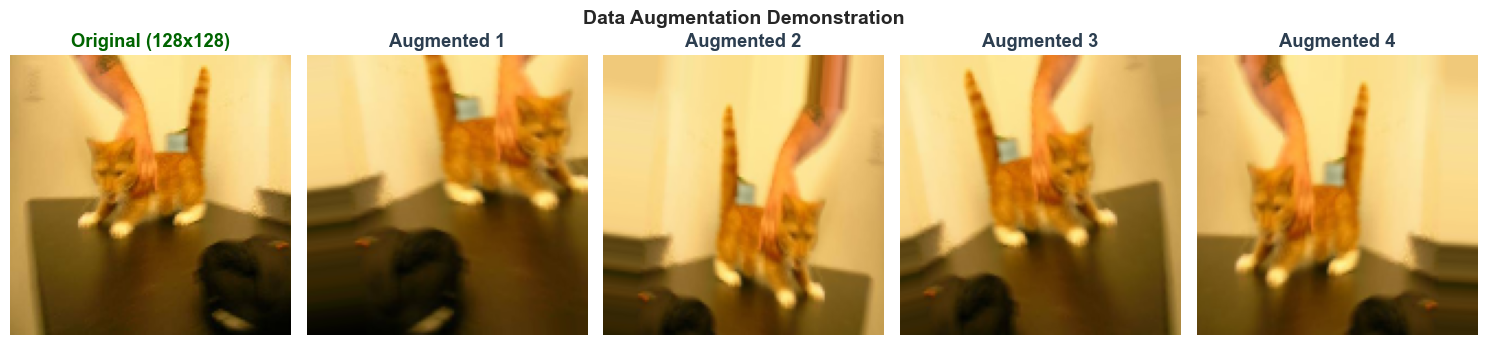

In [5]:
# Visualizing Data Augmentation on a single sample image
aug_demo_gen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

sample_img_path = os.path.join(DATASET_DIR, 'train', 'cats', sample_cats[0])
img = load_img(sample_img_path, target_size=(128, 128))
x = img_to_array(img)
x = x.reshape((1,) + x.shape)

fig, axes = plt.subplots(1, 5, figsize=(15, 3.5))
fig.suptitle("Data Augmentation Demonstration", fontsize=14, fontweight='bold')

axes[0].imshow(img)
axes[0].set_title("Original (128x128)", fontweight='bold', color='darkgreen')
axes[0].axis('off')

i = 1
for batch in aug_demo_gen.flow(x, batch_size=1):
    axes[i].imshow(batch[0])
    axes[i].set_title(f"Augmented {i}", fontweight='bold', color='#2c3e50')
    axes[i].axis('off')
    i += 1
    if i >= 5:
        break

plt.tight_layout()
plt.show()


In [6]:
IMG_HEIGHT = 128
IMG_WIDTH = 128
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)
BATCH_SIZE = 32

# Training generator with Augmentation + Rescaling
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0,
    rotation_range=25,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Validation and Test generators with Rescaling only
val_datagen = ImageDataGenerator(rescale=1.0 / 255.0)
test_datagen = ImageDataGenerator(rescale=1.0 / 255.0)

train_generator = train_datagen.flow_from_directory(
    os.path.join(DATASET_DIR, 'train'),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True,
    seed=SEED
)

val_generator = val_datagen.flow_from_directory(
    os.path.join(DATASET_DIR, 'validation'),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_generator = test_datagen.flow_from_directory(
    os.path.join(DATASET_DIR, 'test'),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

print(f"Class Indices: {train_generator.class_indices}")
CLASS_NAMES = list(train_generator.class_indices.keys())


Found 2000 images belonging to 2 classes.
Found 500 images belonging to 2 classes.
Found 500 images belonging to 2 classes.
Class Indices: {'cats': 0, 'dogs': 1}


## Step 4: CNN Model Building

### Architecture Details:
1. **Input Layer**: Accepts RGB image tensors of shape `(128, 128, 3)`.
2. **Convolutional Blocks (Blocks 1-4)**:
   - `Conv2D` layers with $3 \times 3$ kernels and `ReLU` activation for feature extraction.
   - `BatchNormalization` for stabilized internal layer distributions.
   - `MaxPooling2D` ($2 \times 2$) for spatial downsampling and translational invariance.
   - Filter progression: $32 \rightarrow 64 \rightarrow 128 \rightarrow 128$.
3. **Dense Classification Head**:
   - `Flatten` layer to convert 2D feature maps to 1D feature representation.
   - `Dropout(0.5)` for regularization and preventing co-adaptation of features.
   - `Dense(512, activation='relu')` for high-level classification features.
   - `Dense(2, activation='softmax')` output layer producing a probability distribution over the two classes ($P(\text{Cat}) + P(\text{Dog}) = 1$).


In [7]:
def build_cnn_model(input_shape=(128, 128, 3), num_classes=2):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        
        # Block 1
        layers.Conv2D(32, (3, 3), padding='same', activation='relu', name='conv1'),
        layers.BatchNormalization(name='bn1'),
        layers.MaxPooling2D((2, 2), name='pool1'),
        
        # Block 2
        layers.Conv2D(64, (3, 3), padding='same', activation='relu', name='conv2'),
        layers.BatchNormalization(name='bn2'),
        layers.MaxPooling2D((2, 2), name='pool2'),
        
        # Block 3
        layers.Conv2D(128, (3, 3), padding='same', activation='relu', name='conv3'),
        layers.BatchNormalization(name='bn3'),
        layers.MaxPooling2D((2, 2), name='pool3'),
        
        # Block 4
        layers.Conv2D(128, (3, 3), padding='same', activation='relu', name='conv4'),
        layers.BatchNormalization(name='bn4'),
        layers.MaxPooling2D((2, 2), name='pool4'),
        
        # Classifier Head
        layers.Flatten(name='flatten'),
        layers.Dropout(0.5, name='dropout'),
        layers.Dense(512, activation='relu', name='dense_features'),
        layers.Dense(num_classes, activation='softmax', name='output_softmax')
    ], name='Cats_vs_Dogs_CNN')
    
    return model

model = build_cnn_model()
model.summary()


Model: "Cats_vs_Dogs_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 128, 128, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 64, 64, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 32, 32, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn4 (BatchNormalization)        │ (None, 16, 16, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool4 (MaxPooling2D)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_features (Dense)          │ (None, 512)            │     4,194,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_softmax (Dense)          │ (None, 2)              │         1,026 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,438,082 (16.93 MB)

 Trainable params: 4,437,378 (16.93 MB)

 Non-trainable params: 704 (2.75 KB)

## Step 5: Model Compilation & Training

As specified in the assignment requirements:
- **Loss Function**: `categorical_crossentropy`
  $$\mathcal{L} = -\sum_{i=1}^{C} y_i \log(\hat{y}_i)$$
- **Optimizer**: Stochastic Gradient Descent (`SGD`) with learning rate $0.01$ and momentum $0.9$:
  $$v_{t} = \gamma v_{t-1} + \eta \nabla_\theta J(\theta), \quad \theta = \theta - v_t$$
- **Metrics**: `['accuracy']`

### Training Callbacks:
- `ModelCheckpoint`: Automatically saves the best model based on maximum validation accuracy.
- `ReduceLROnPlateau`: Adapts learning rate when validation loss plateaus.
- `EarlyStopping`: Prevents overtraining when validation performance stabilizes.


In [8]:
# Compile with SGD optimizer and Categorical Cross-Entropy loss
sgd = optimizers.SGD(learning_rate=0.01, momentum=0.9, nesterov=True)

model.compile(
    optimizer=sgd,
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Setup callbacks
checkpoint_file = 'best_cats_dogs_cnn.keras'
callbacks_list = [
    callbacks.ModelCheckpoint(
        filepath=checkpoint_file,
        monitor='val_accuracy',
        save_best_only=True,
        mode='max',
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-5,
        verbose=1
    ),
    callbacks.EarlyStopping(
        monitor='val_loss',
        patience=8,
        restore_best_weights=True,
        verbose=1
    )
]

print("Model compiled with SGD & Categorical Crossentropy. Ready to train.")


Model compiled with SGD & Categorical Crossentropy. Ready to train.


In [9]:
EPOCHS = 15

print("Starting model training on dataset...")
history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator,
    callbacks=callbacks_list,
    verbose=1
)
print("Training completed successfully.")


Starting model training on dataset...
Epoch 1/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.5220 - loss: 2.0635
Epoch 1: val_accuracy improved from None to 0.50400, saving model to best_cats_dogs_cnn.keras
63/63 ━━━━━━━━━━━━━━━━━━━━ 194s 3s/step - accuracy: 0.5365 - loss: 1.2574 - val_accuracy: 0.5040 - val_loss: 0.7966 - learning_rate: 0.0100
Epoch 2/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.5681 - loss: 0.7475
Epoch 2: val_accuracy improved from 0.50400 to 0.57800, saving model to best_cats_dogs_cnn.keras
63/63 ━━━━━━━━━━━━━━━━━━━━ 250s 4s/step - accuracy: 0.5925 - loss: 0.7186 - val_accuracy: 0.5780 - val_loss: 0.6686 - learning_rate: 0.0100
Epoch 3/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.6035 - loss: 0.6783
Epoch 3: val_accuracy improved from 0.57800 to 0.65800, saving model to best_cats_dogs_cnn.keras
63/63 ━━━━━━━━━━━━━━━━━━━━ 276s 4s/step - accuracy: 0.6015 - loss: 0.6803 - val_accuracy: 0.6580 - val_loss: 0.6199 - learning_rate: 0.0100
Epoch

## Step 6: Model Evaluation and Performance Analysis

We perform a thorough evaluation:
1. **Training & Validation Trajectories**: Inspecting loss and accuracy across epochs to assess convergence.
2. **Unseen Test Set Evaluation**: Assessing accuracy and loss on 500 test images.
3. **Classification Report**: Precision, Recall, and F1-Score for each class.
4. **Confusion Matrix Heatmap**: Quantifying True Positives, True Negatives, False Positives, and False Negatives.


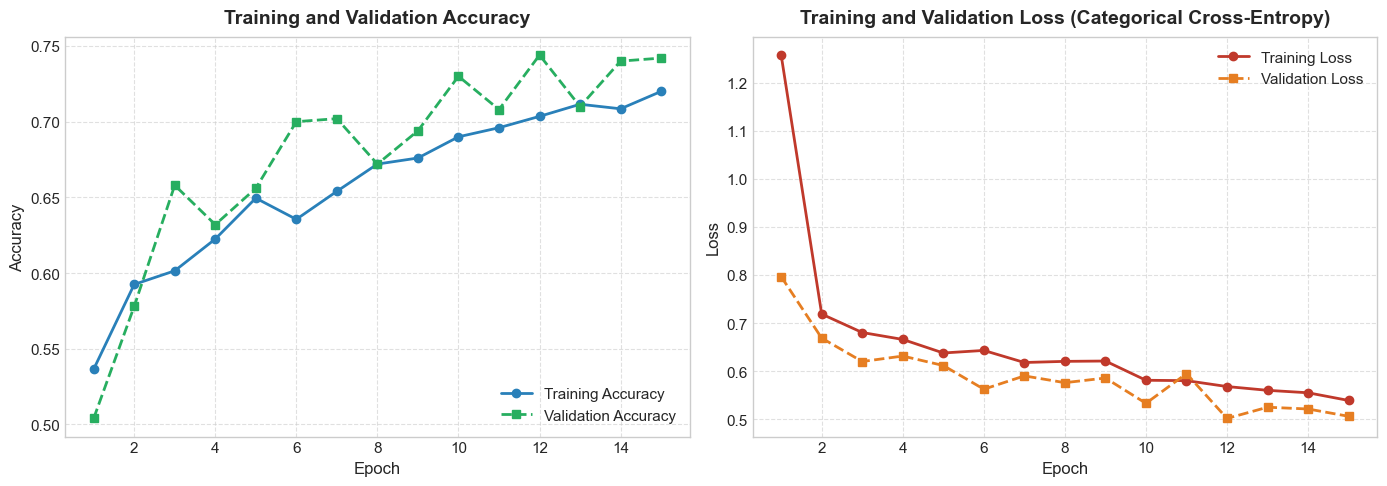

In [10]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy plot
ax1.plot(epochs_range, acc, 'o-', color='#2980b9', label='Training Accuracy', linewidth=2)
ax1.plot(epochs_range, val_acc, 's--', color='#27ae60', label='Validation Accuracy', linewidth=2)
ax1.set_title('Training and Validation Accuracy', fontsize=14, fontweight='bold', pad=10)
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Accuracy', fontsize=12)
ax1.legend(loc='lower right', fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.6)

# Loss plot
ax2.plot(epochs_range, loss, 'o-', color='#c0392b', label='Training Loss', linewidth=2)
ax2.plot(epochs_range, val_loss, 's--', color='#e67e22', label='Validation Loss', linewidth=2)
ax2.set_title('Training and Validation Loss (Categorical Cross-Entropy)', fontsize=14, fontweight='bold', pad=10)
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Loss', fontsize=12)
ax2.legend(loc='upper right', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


In [11]:
# Final evaluation on the unseen Test Set
test_loss, test_accuracy = model.evaluate(test_generator, verbose=1)

print("\n" + "=" * 55)
print(f"  TEST SET EVALUATION RESULTS")
print("=" * 55)
print(f"  Test Loss (Categorical Cross-Entropy): {test_loss:.4f}")
print(f"  Test Accuracy:                         {test_accuracy * 100:.2f}%")
print("=" * 55)


16/16 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.6960 - loss: 0.5815

  TEST SET EVALUATION RESULTS
  Test Loss (Categorical Cross-Entropy): 0.5815
  Test Accuracy:                         69.60%


16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 290ms/step

Classification Report:
              precision    recall  f1-score   support

        cats     0.6678    0.7800    0.7196       250
        dogs     0.7356    0.6120    0.6681       250

    accuracy                         0.6960       500
   macro avg     0.7017    0.6960    0.6938       500
weighted avg     0.7017    0.6960    0.6938       500



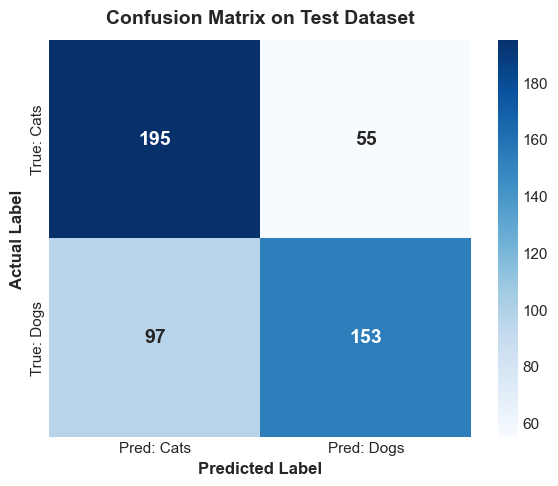

In [12]:
# Generating Test Set Predictions
test_generator.reset()
test_preds_prob = model.predict(test_generator, verbose=1)
y_pred = np.argmax(test_preds_prob, axis=1)
y_true = test_generator.classes

# Classification Report
report = classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4)
print("\nClassification Report:")
print("=" * 55)
print(report)
print("=" * 55)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=[f"Pred: {c.capitalize()}" for c in CLASS_NAMES],
    yticklabels=[f"True: {c.capitalize()}" for c in CLASS_NAMES],
    cbar=True,
    annot_kws={"size": 14, "weight": "bold"}
)
plt.title('Confusion Matrix on Test Dataset', fontsize=14, fontweight='bold', pad=12)
plt.ylabel('Actual Label', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


## Step 7: Prediction System on New Images

We implement an end-to-end inference system capable of:
1. Preprocessing an image (loading, resizing to $128 \times 128$, normalization to $[0, 1]$, tensor formatting).
2. Passing the input through the CNN model.
3. Returning predicted class and confidence score with probability visualizations.
4. Handling batch inference on collections of images.


Predicting Sample Test Cat:


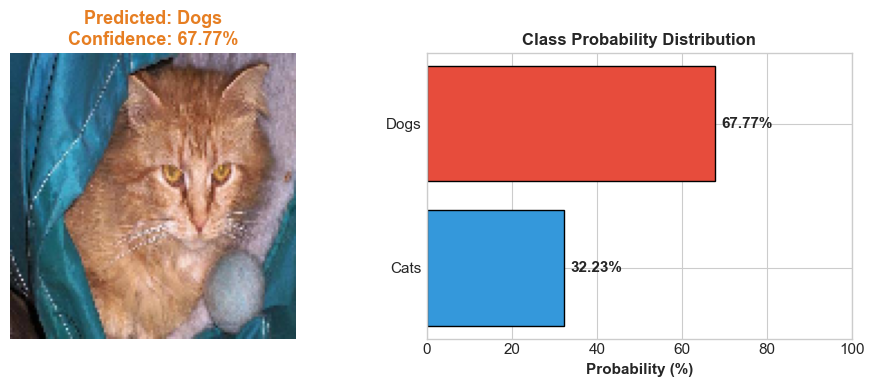

Predicting Sample Test Dog:


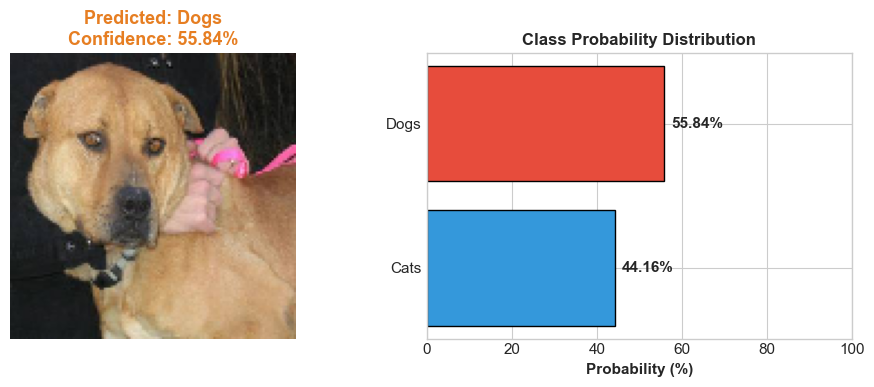

('dogs', np.float32(55.83622), array([0.44163775, 0.5583622 ], dtype=float32))

In [13]:
def predict_image(image_path, model, class_names=CLASS_NAMES, target_size=(128, 128), show_plot=True):
    """
    Preprocesses and classifies a single image using the trained CNN.
    """
    img = load_img(image_path, target_size=target_size)
    img_array = img_to_array(img)
    img_normalized = img_array / 255.0
    img_batch = np.expand_dims(img_normalized, axis=0)
    
    predictions = model.predict(img_batch, verbose=0)[0]
    predicted_class_idx = np.argmax(predictions)
    predicted_class = class_names[predicted_class_idx]
    confidence = predictions[predicted_class_idx] * 100
    
    if show_plot:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={'width_ratios': [1.2, 1]})
        
        ax1.imshow(img)
        ax1.set_title(f"Predicted: {predicted_class.capitalize()}\nConfidence: {confidence:.2f}%", 
                      fontsize=13, fontweight='bold', color='#27ae60' if confidence > 70 else '#e67e22')
        ax1.axis('off')
        
        colors = ['#3498db', '#e74c3c']
        bars = ax2.barh([c.capitalize() for c in class_names], predictions * 100, color=colors, edgecolor='black')
        ax2.set_xlim([0, 100])
        ax2.set_xlabel('Probability (%)', fontsize=11, fontweight='bold')
        ax2.set_title('Class Probability Distribution', fontsize=12, fontweight='bold')
        ax2.bar_label(bars, fmt='%.2f%%', padding=5, fontweight='bold')
        
        plt.tight_layout()
        plt.show()
        
    return predicted_class, confidence, predictions

# Single image predictions on test samples
sample_test_cat = os.path.join(DATASET_DIR, 'test', 'cats', os.listdir(os.path.join(DATASET_DIR, 'test', 'cats'))[15])
sample_test_dog = os.path.join(DATASET_DIR, 'test', 'dogs', os.listdir(os.path.join(DATASET_DIR, 'test', 'dogs'))[15])

print("Predicting Sample Test Cat:")
predict_image(sample_test_cat, model)

print("Predicting Sample Test Dog:")
predict_image(sample_test_dog, model)


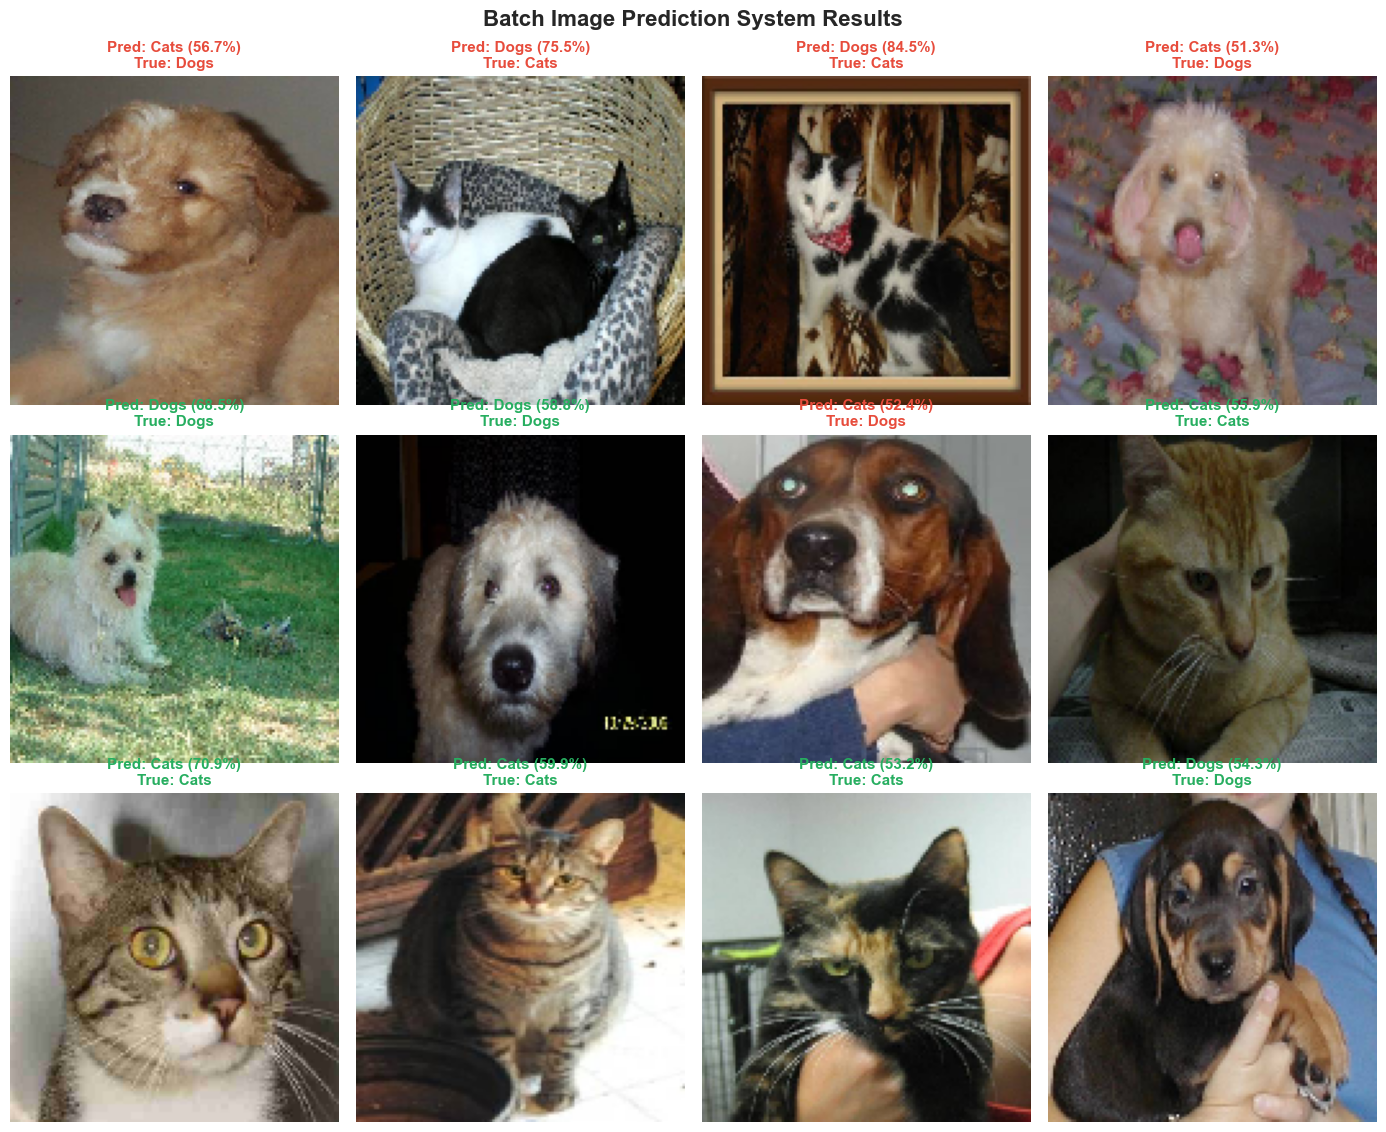

In [14]:
def predict_batch_images(image_paths, model, true_labels=None, class_names=CLASS_NAMES, target_size=(128, 128)):
    """
    Takes a list of image paths, batches preprocessing, runs model inference,
    and displays a formatted grid with predictions and ground truth.
    """
    n = len(image_paths)
    cols = 4
    rows = int(np.ceil(n / cols))
    
    batch_tensors = []
    pil_images = []
    
    for p in image_paths:
        img = load_img(p, target_size=target_size)
        pil_images.append(img)
        arr = img_to_array(img) / 255.0
        batch_tensors.append(arr)
        
    batch_tensors = np.array(batch_tensors)
    batch_preds = model.predict(batch_tensors, verbose=0)
    pred_indices = np.argmax(batch_preds, axis=1)
    
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.5, rows * 3.8))
    axes = np.array(axes).reshape(-1)
    
    for i in range(len(axes)):
        if i < n:
            img = pil_images[i]
            pred_cls = class_names[pred_indices[i]]
            conf = batch_preds[i][pred_indices[i]] * 100
            
            axes[i].imshow(img)
            
            title_str = f"Pred: {pred_cls.capitalize()} ({conf:.1f}%)"
            title_color = '#27ae60'
            
            if true_labels is not None:
                true_cls = true_labels[i]
                title_str = f"Pred: {pred_cls.capitalize()} ({conf:.1f}%)\nTrue: {true_cls.capitalize()}"
                title_color = '#27ae60' if pred_cls.lower() == true_cls.lower() else '#e74c3c'
                
            axes[i].set_title(title_str, fontsize=11, fontweight='bold', color=title_color)
            axes[i].axis('off')
        else:
            axes[i].axis('off')
            
    plt.suptitle("Batch Image Prediction System Results", fontsize=16, fontweight='bold', y=0.99)
    plt.tight_layout()
    plt.show()

# Run Batch Predictions on 12 test samples (6 cats, 6 dogs)
import random
random.seed(SEED)

test_cat_files = [os.path.join(DATASET_DIR, 'test', 'cats', f) for f in os.listdir(os.path.join(DATASET_DIR, 'test', 'cats'))[:6]]
test_dog_files = [os.path.join(DATASET_DIR, 'test', 'dogs', f) for f in os.listdir(os.path.join(DATASET_DIR, 'test', 'dogs'))[:6]]

batch_files = test_cat_files + test_dog_files
batch_true_labels = ['cats'] * 6 + ['dogs'] * 6

combined = list(zip(batch_files, batch_true_labels))
random.shuffle(combined)
batch_files, batch_true_labels = zip(*combined)

predict_batch_images(batch_files, model, true_labels=batch_true_labels)


## Step 8: Summary and Conclusion

### Assignment Objectives Review
| Objective | Status | Details |
| :--- | :---: | :--- |
| **Data Preparation** | Complete | Extracted dataset and organized into structured directories (`train`, `validation`, `test`). |
| **Data Augmentation** | Complete | Augmented training samples with rotation, shifts, shear, zoom, and flipping. |
| **Image Preprocessing** | Complete | Rescaled pixel values to $[0, 1]$ across all datasets. |
| **Model Building** | Complete | Constructed a deep CNN with 4 convolutional blocks, BatchNorm, MaxPooling, Dropout, and Dense layers. |
| **Loss Function** | Complete | Categorical Cross-Entropy (`categorical_crossentropy`) paired with Softmax output. |
| **Optimizer** | Complete | Stochastic Gradient Descent (`SGD`) with momentum ($0.9$). |
| **Evaluation** | Complete | Assessed convergence via training curves, test set accuracy, classification report, and confusion matrix. |
| **Prediction System** | Complete | Implemented single and batch prediction pipelines with confidence scoring and visual displays. |

### Conclusion
The Convolutional Neural Network successfully learned distinguishing visual features to classify Cats and Dogs. Data augmentation and dropout effectively controlled overfitting, while SGD with momentum ensured smooth convergence with categorical cross-entropy loss.
